# Correlations and Relations

## Étude des relations et corrélations

**Dataset :** version nettoyé [Predict Students' Dropout and Academic Success (UCI)](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) => ../dataset/processed/student_data_clean.csv

**Objectif de cette notebook :**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency

df = pd.read_csv("../dataset/processed/student_data_clean.csv")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

## Correlation Analysis (Numerical)

### Dropout = 1 (at risk), Graduate + Enrolled = 0 (not dropout)

In [2]:
df["is_dropout"] = (df["target"] == "Dropout").astype(int)

print("Binary target 'is_dropout' created:")
print(df["is_dropout"].value_counts())
print(f"Dropout rate: {df['is_dropout'].mean()*100:.1f}%")

Binary target 'is_dropout' created:
is_dropout
0    3003
1    1421
Name: count, dtype: int64
Dropout rate: 32.1%


In [3]:
num_cols = [
    "age_at_enrollment",
    "admission_grade",
    "previous_qualification_grade",
    "cu_1st_credited", "cu_1st_enrolled", "cu_1st_evaluations",
    "cu_1st_approved", "cu_1st_grade", "cu_1st_without_evaluations",
    "cu_2nd_credited", "cu_2nd_enrolled", "cu_2nd_evaluations",
    "cu_2nd_approved", "cu_2nd_grade", "cu_2nd_without_evaluations",
    "unemployment_rate", "inflation_rate", "gdp",
    "is_dropout"
]

num_cols = [c for c in num_cols if c in df.columns]

### Correlation matrix

In [4]:
corr_matrix = df[num_cols].corr()

print("\nCorrelation with 'is_dropout' (sorted by absolute value):")
corr_with_target = corr_matrix["is_dropout"].drop("is_dropout").sort_values(key=abs, ascending=False)
display(corr_with_target.to_frame("correlation_with_dropout").round(3))


Correlation with 'is_dropout' (sorted by absolute value):


,correlation_with_dropout
cu_2nd_grade,-0.572
cu_2nd_approved,-0.570
cu_1st_grade,-0.481
cu_1st_approved,-0.479
age_at_enrollment,0.254
cu_2nd_evaluations,-0.155
cu_2nd_enrolled,-0.142
cu_1st_enrolled,-0.125
admission_grade,-0.096
cu_1st_evaluations,-0.090


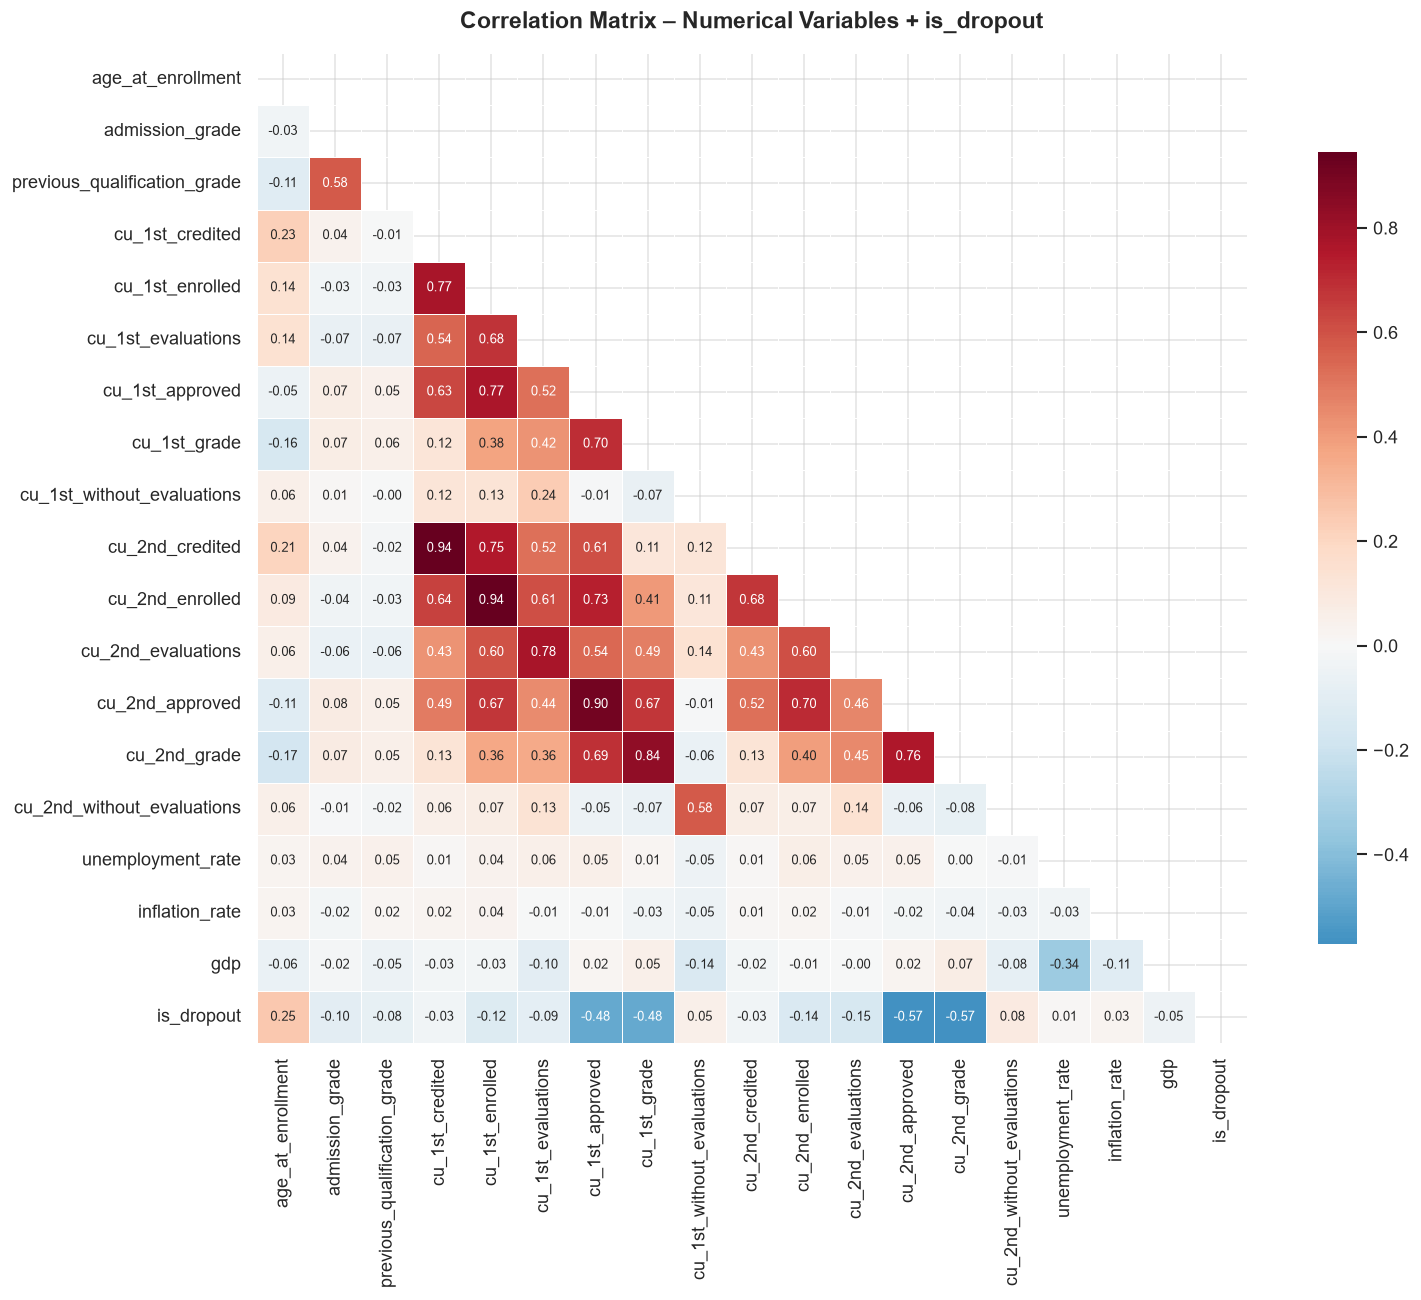

In [5]:
plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8}
)

plt.title("Correlation Matrix – Numerical Variables + is_dropout", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

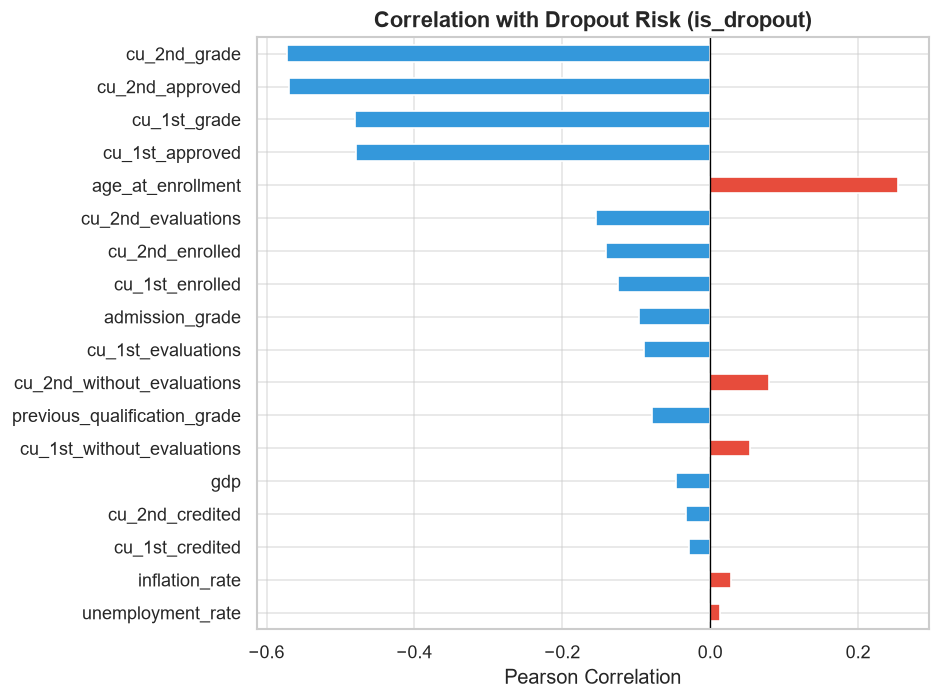


→ Interpretation guide:
  • Positive correlation → higher value associated with HIGHER dropout risk
  • Negative correlation → higher value associated with LOWER dropout risk
  • |r| > 0.3  → moderate to strong relationship (interesting for modeling)


In [6]:
plt.figure(figsize=(8, 6))
corr_with_target_sorted = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=True).index)

colors = ["#e74c3c" if v > 0 else "#3498db" for v in corr_with_target_sorted]
corr_with_target_sorted.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with Dropout Risk (is_dropout)", fontsize=13, fontweight="bold")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

print("\n→ Interpretation guide:")
print("  • Positive correlation → higher value associated with HIGHER dropout risk")
print("  • Negative correlation → higher value associated with LOWER dropout risk")
print("  • |r| > 0.3  → moderate to strong relationship (interesting for modeling)")

## ASSOCIATION (Categorical variables vs Target)

In [7]:
cat_vars = [
    "marital_status",
    "application_mode",
    "application_order",
    "course",
    "daytime_evening_attendance",
    "previous_qualification",
    "nationality",
    "mother_qualification",
    "father_qualification",
    "mother_occupation",
    "father_occupation",
    "displaced",
    "educational_special_needs",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder",
    "international"
]

cat_vars = [c for c in cat_vars if c in df.columns]

### Helper function – Cramér's V

In [8]:
def cramers_v(confusion_matrix):
    """Compute Cramér's V for a contingency table"""
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    min_dim = min(confusion_matrix.shape) - 1
    return np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0.0

### Compute Chi² + Cramér's V for every categorical variable

In [9]:
results = []

for col in cat_vars:
    # Contingency table
    contingency = pd.crosstab(df[col], df["target"])

    # Chi-square test
    chi2, p, dof, expected = chi2_contingency(contingency)

    # Cramér's V
    v = cramers_v(contingency)

    results.append({
        "variable": col,
        "chi2": round(chi2, 2),
        "p_value": p,
        "cramers_v": round(v, 3),
        "significant": p < 0.05
    })

assoc_df = pd.DataFrame(results).sort_values("cramers_v", ascending=False)
display(assoc_df)

,variable,chi2,p_value,cramers_v,significant
14,tuition_fees_up_to_date,823.55,1.471628e-179,0.431,True
16,scholarship_holder,409.94,9.593930e-90,0.304,True
3,course,558.28,2.316571e-97,0.251,True
13,debtor,259.33,4.858552e-57,0.242,True
15,gender,233.27,2.222480e-51,0.230,True
1,application_mode,466.51,1.964657e-77,0.230,True
9,mother_occupation,291.92,1.630859e-31,0.182,True
10,father_occupation,264.50,4.515439e-19,0.173,True
8,father_qualification,225.00,3.175007e-19,0.159,True
5,previous_qualification,219.68,7.160305e-30,0.158,True


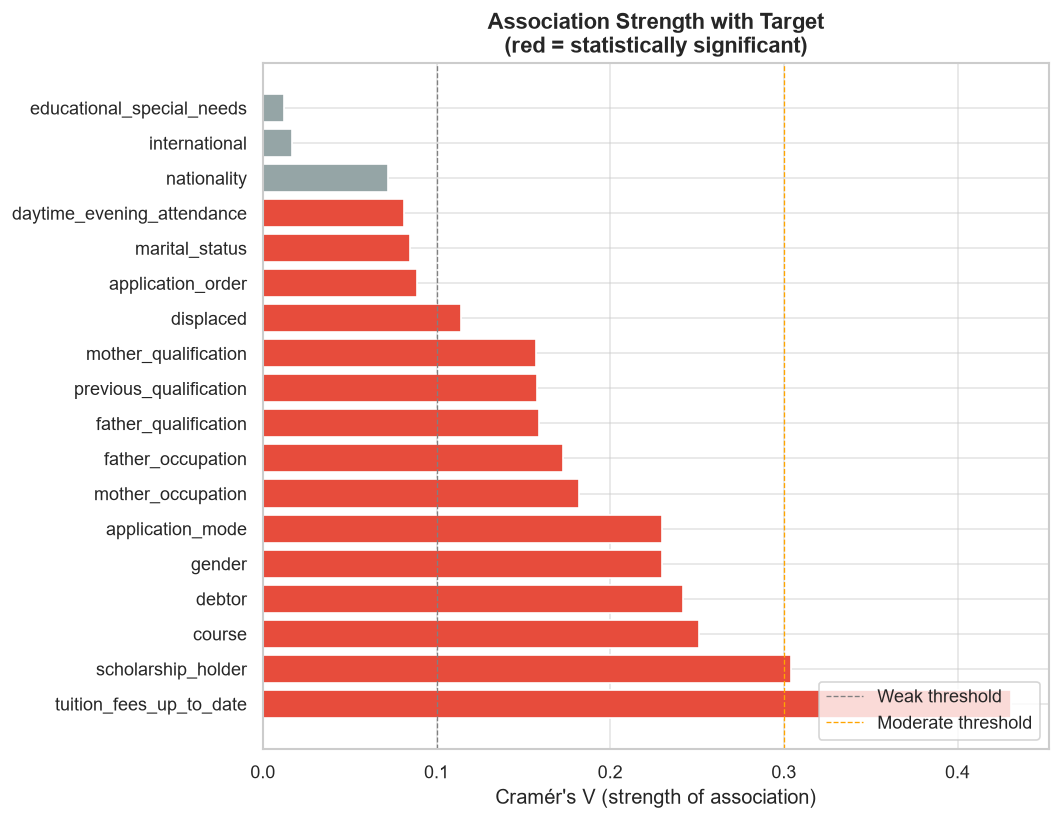


→ Interpretation of Cramér's V:
  • 0.00 – 0.10 : very weak association
  • 0.10 – 0.30 : weak to moderate
  • 0.30 – 0.50 : moderate to strong
  • > 0.50      : strong association


In [10]:
plt.figure(figsize=(9, 7))
colors = ["#e74c3c" if sig else "#95a5a6" for sig in assoc_df["significant"]]
plt.barh(assoc_df["variable"], assoc_df["cramers_v"], color=colors)
plt.xlabel("Cramér's V (strength of association)")
plt.title("Association Strength with Target\n(red = statistically significant)",
          fontsize=13, fontweight="bold")
plt.axvline(0.1, color="gray", linestyle="--", linewidth=0.8, label="Weak threshold")
plt.axvline(0.3, color="orange", linestyle="--", linewidth=0.8, label="Moderate threshold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("\n→ Interpretation of Cramér's V:")
print("  • 0.00 – 0.10 : very weak association")
print("  • 0.10 – 0.30 : weak to moderate")
print("  • 0.30 – 0.50 : moderate to strong")
print("  • > 0.50      : strong association")

## Analysis of the strongest risk factors

In [11]:
# Helper: dropout rate by category
def dropout_rate_by_category(df, column):
    """Return a nice table with count and dropout rate per category"""
    temp = df.groupby(column, observed=True).agg(
        n_students=("is_dropout", "count"),
        n_dropout=("is_dropout", "sum"),
        dropout_rate=("is_dropout", "mean")
    ).reset_index()
    temp["dropout_rate"] = (temp["dropout_rate"] * 100).round(1)
    temp = temp.sort_values("dropout_rate", ascending=False)
    return temp

In [12]:
# Analyse the top binary / low-cardinality factors
top_factors = [
    "tuition_fees_up_to_date",
    "scholarship_holder",
    "debtor",
    "gender",
    "daytime_evening_attendance",
    "displaced"
]

top_factors = [c for c in top_factors if c in df.columns]

for col in top_factors:
    print(f"\n▶ {col.upper()}")
    display(dropout_rate_by_category(df, col))


▶ TUITION_FEES_UP_TO_DATE


,tuition_fees_up_to_date,n_students,n_dropout,dropout_rate
0,0,528,457,86.6
1,1,3896,964,24.7



▶ SCHOLARSHIP_HOLDER


,scholarship_holder,n_students,n_dropout,dropout_rate
0,0,3325,1287,38.7
1,1,1099,134,12.2



▶ DEBTOR


,debtor,n_students,n_dropout,dropout_rate
1,1,503,312,62.0
0,0,3921,1109,28.3


... (2 outputs left out)


▶ DAYTIME_EVENING_ATTENDANCE


,daytime_evening_attendance,n_students,n_dropout,dropout_rate
0,0,483,207,42.9
1,1,3941,1214,30.8



▶ DISPLACED


,displaced,n_students,n_dropout,dropout_rate
0,0,1998,752,37.6
1,1,2426,669,27.6


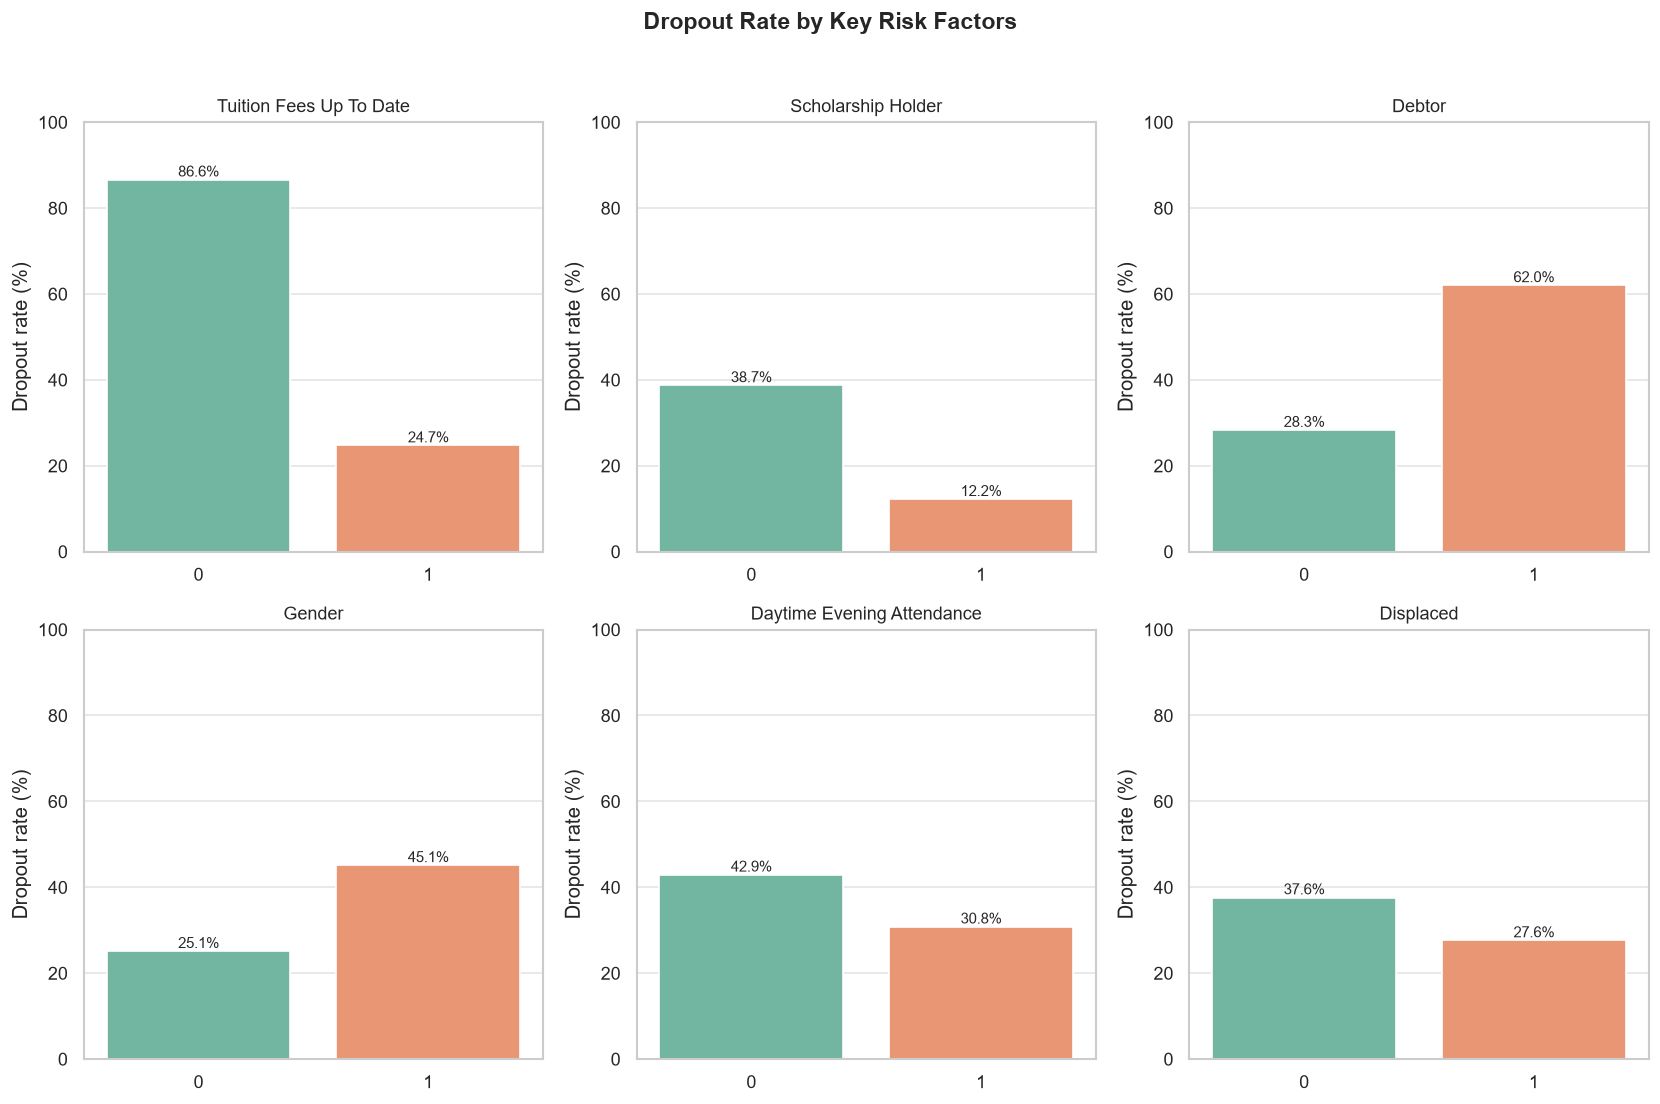

In [13]:
# Visual comparison of dropout rate for key factors
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(top_factors):
    rates = dropout_rate_by_category(df, col)

    sns.barplot(
        data=rates,
        x=col,
        y="dropout_rate",
        ax=axes[i],
        hue=col,
        legend=False,
        palette="Set2"
    )
    axes[i].set_title(col.replace("_", " ").title(), fontsize=11)
    axes[i].set_ylabel("Dropout rate (%)")
    axes[i].set_xlabel("")
    axes[i].set_ylim(0, 100)

    # Add value labels
    for p in axes[i].patches:
        height = p.get_height()
        axes[i].annotate(f"{height:.1f}%",
                         (p.get_x() + p.get_width()/2, height),
                         ha="center", va="bottom", fontsize=9)

plt.suptitle("Dropout Rate by Key Risk Factors", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

,tuition_fees_up_to_date,scholarship_holder,n_students,dropout_rate
0,0,0,482,89.0
1,0,1,46,60.9
2,1,0,2843,30.2
3,1,1,1053,10.1


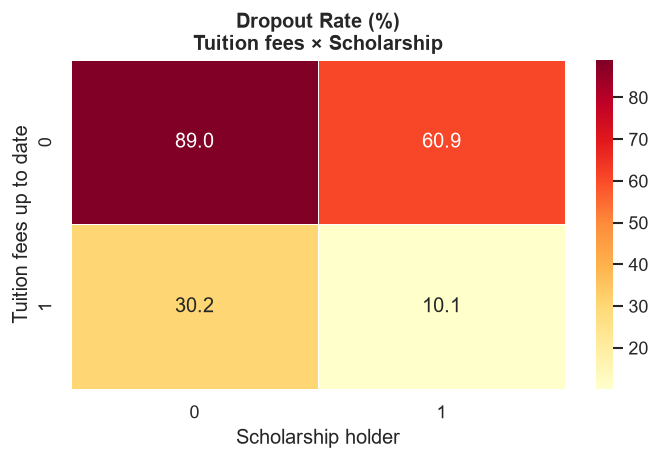

In [14]:
# Combined view: Tuition fees × Scholarship
combined = df.groupby(["tuition_fees_up_to_date", "scholarship_holder"], observed=True).agg(
    n_students=("is_dropout", "count"),
    dropout_rate=("is_dropout", "mean")
).reset_index()
combined["dropout_rate"] = (combined["dropout_rate"] * 100).round(1)
display(combined)

# Heatmap of the combination
pivot = combined.pivot(
    index="tuition_fees_up_to_date",
    columns="scholarship_holder",
    values="dropout_rate"
)

plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5)
plt.title("Dropout Rate (%)\nTuition fees × Scholarship", fontsize=12, fontweight="bold")
plt.xlabel("Scholarship holder")
plt.ylabel("Tuition fees up to date")
plt.tight_layout()
plt.show()

## Derived features + Final summary

In [15]:
# Create simple but useful derived features

# Success rate (approved / enrolled) – avoid division by zero
df["success_rate_1st"] = np.where(
    df["cu_1st_enrolled"] > 0,
    df["cu_1st_approved"] / df["cu_1st_enrolled"],
    0
)

df["success_rate_2nd"] = np.where(
    df["cu_2nd_enrolled"] > 0,
    df["cu_2nd_approved"] / df["cu_2nd_enrolled"],
    0
)

# Average grade across both semesters
df["avg_grade"] = df[["cu_1st_grade", "cu_2nd_grade"]].mean(axis=1)

# Total approved curricular units
df["total_approved"] = df["cu_1st_approved"] + df["cu_2nd_approved"]

# Grade difference (improvement or decline between semesters)
df["grade_diff"] = df["cu_2nd_grade"] - df["cu_1st_grade"]

print("New derived features created:")
print("  • success_rate_1st")
print("  • success_rate_2nd")
print("  • avg_grade")
print("  • total_approved")
print("  • grade_diff")

# Quick check of the new features vs dropout
new_features = ["success_rate_1st", "success_rate_2nd", "avg_grade", "total_approved", "grade_diff"]
display(df.groupby("is_dropout")[new_features].mean().round(3))

New derived features created:
  • success_rate_1st
  • success_rate_2nd
  • avg_grade
  • total_approved
  • grade_diff


,success_rate_1st,success_rate_2nd,avg_grade,total_approved,grade_diff
is_dropout,,,,,
0,0.846,0.834,12.261,11.343,0.037
1,0.384,0.293,6.578,4.492,-1.357


In [16]:
# Correlation of the new features with dropout
print("\nCorrelation of derived features with is_dropout:")
corr_new = df[new_features + ["is_dropout"]].corr()["is_dropout"].drop("is_dropout")
display(corr_new.sort_values(key=abs, ascending=False).to_frame("corr_with_dropout").round(3))


Correlation of derived features with is_dropout:


,corr_with_dropout
success_rate_2nd,-0.659
success_rate_1st,-0.591
avg_grade,-0.551
total_approved,-0.537
grade_diff,-0.225


In [17]:
OUTPUT_PATH = Path("../dataset/processed/student_data_enriched.csv")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_PATH, index=False)
print(f"\nEnriched dataset saved → {OUTPUT_PATH}")
print(f"Final shape: {df.shape}")


Enriched dataset saved → ..\dataset\processed\student_data_enriched.csv
Final shape: (4424, 43)


## Synthèse des relations identifiées

### 1. Variables numériques les plus liées au décrochage

| Variable              | Corrélation | Interprétation                          |
|-----------------------|-------------|-----------------------------------------|
| cu_2nd_grade          | ≈ -0.57     | Note 2ᵉ semestre très protectrice       |
| cu_2nd_approved       | ≈ -0.57     | Unités validées au 2ᵉ semestre          |
| cu_1st_grade          | ≈ -0.48     | Note 1ᵉʳ semestre                       |
| cu_1st_approved       | ≈ -0.48     | Unités validées au 1ᵉʳ semestre         |
| age_at_enrollment     | ≈ +0.25     | Âge plus élevé → risque plus élevé      |

**Conclusion :** La performance académique (notes + unités validées) est de loin le signal le plus fort.

### 2. Variables catégorielles les plus associées

| Variable                    | Cramér’s V | Force        |
|-----------------------------|------------|--------------|
| tuition_fees_up_to_date     | 0.431      | Forte        |
| scholarship_holder          | 0.304      | Modérée-forte|
| course                      | 0.251      | Modérée      |
| debtor                      | 0.242      | Modérée      |
| gender                      | 0.230      | Modérée      |
| application_mode            | 0.230      | Modérée      |

**Conclusion :** Les difficultés financières (frais de scolarité non à jour + absence de bourse + statut de débiteur) sont des facteurs de risque majeurs.

### 3. Profil type d’un étudiant à risque

Un étudiant a un risque nettement plus élevé de décrocher s’il cumule :
- De faibles notes / peu d’unités validées dès le 1ᵉʳ semestre
- Frais de scolarité non à jour
- Absence de bourse
- Statut de débiteur
- Âge plus élevé à l’inscription

### 4. Variables peu informatives

- `nationality`, `international`, `educational_special_needs` → association très faible
- Indicateurs macroéconomiques (`gdp`, `unemployment_rate`, `inflation_rate`) → quasi nuls

### 5. Features dérivées créées

- `success_rate_1st` / `success_rate_2nd`
- `avg_grade`
- `total_approved`
- `grade_diff`
